# Custom CNN (KneeCNN) trained from scratch

We train our own CNN, **KneeCNN**, from scratch. The code follows `02_transfer_learning.ipynb` (same sections, data code, training loop and plots), so both notebooks can be compared directly.

**Class imbalance:** as agreed in the team, we use **mild augmentation + weighted sampler** (the data method of `02_transfer_learning.ipynb`). The comparison of data methods is in `01_custom_cnn_comparison.ipynb`.

**In this notebook:**
1. Try a few combinations of **batch size** and **learning rate** and compare them on the **validation set**.
2. Use the best combination for the **final test** (only once).

Quick test: `USE_SAMPLE_DATA = True`. Real run: `USE_SAMPLE_DATA = False` (Colab with a T4 GPU).

## Import everything in colab

The following cell sets up the project in a fresh Colab runtime. This clones the repository, loads the dependencies and configures settings.

In [1]:
!git clone https://github.com/michael-duer/medical-image-classification.git
%cd medical-image-classification

Cloning into 'medical-image-classification'...
remote: Enumerating objects: 8361, done.
remote: Total 8361 (delta 0), reused 0 (delta 0), pack-reused 8361 (from 2)
Receiving objects: 100% (8361/8361), 274.96 MiB | 24.98 MiB/s, done.
Resolving deltas: 100% (33/33), done.
Updating files: 100% (8284/8284), done.
/content/medical-image-classification


In [2]:
import random
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from PIL import Image
from sklearn.metrics import accuracy_score, confusion_matrix, roc_auc_score
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, Dataset, WeightedRandomSampler
from torchvision import datasets, transforms
from tqdm.auto import tqdm

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__)
print("Device:", DEVICE)
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

# Set paths
# NEW: True = 150 sample X-rays (quick test), False = real dataset
USE_SAMPLE_DATA = False

if USE_SAMPLE_DATA:
    DATA_DIR = Path('/content/medical-image-classification/example_data/knee_oa_test')
    if not DATA_DIR.exists():
        import zipfile
        zipfile.ZipFile('/content/medical-image-classification/example_data/knee_oa_test.zip').extractall('/content/medical-image-classification/example_data')
    # The sample zip was made on a Mac: delete the hidden "._" files, they are not images
    for mac_file in DATA_DIR.rglob('._*'):
        mac_file.unlink()
else:
    DATA_DIR = Path('/content/medical-image-classification/data')
OUTPUT_DIR = Path('/content/medical-image-classification/output')

if not DATA_DIR.exists():
    raise FileNotFoundError(f"Set DATA_DIR to your actual dataset folder first: {DATA_DIR}")
print('Dataset path:', DATA_DIR.resolve())

PyTorch: 2.11.0+cu130
Device: cuda
GPU: Tesla T4
Dataset path: /content/medical-image-classification/data


## 1. Load and inspect data

The dataset already split the data into `train`, `test` and `val` folders. The same label mapping and normalization will be used by every model. The number of images between classes varies a lot. To handle this we use **mild augmentation** of every training image (rotation ±5°, left–right flip, ±5 % brightness/contrast) and a **weighted sampler** that draws rare grades more often – the same data code as in `02_transfer_learning.ipynb`. Validation and test images are never augmented.

`make_loaders(batch_size)` builds the loaders, so we can try different batch sizes.

In [3]:
from torchvision.datasets.folder import default_loader

# Normalization matches common ImageNet-pretrained ResNet/EfficientNet weights.
# Keep these choices the same in all experiments.
MEAN = (0.485, 0.456, 0.406)
STD = (0.229, 0.224, 0.225)

IMAGE_SIZE = 224
NUM_CLASSES = 5

class ImageSubset(Dataset):
    """ImageFolder-compatible subset that stores explicit (path, label) entries."""
    def __init__(self, samples, transform):
        self.samples = [(str(p), int(y)) for p, y in samples]
        self.transform = transform

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        path, label = self.samples[idx]
        img = default_loader(path)  # RGB
        return self.transform(img), label

# Load datasets
train_source = datasets.ImageFolder(DATA_DIR / 'train')
val_source = datasets.ImageFolder(DATA_DIR / 'val')
test_source = datasets.ImageFolder(DATA_DIR / 'test')

split_samples = {
        'train': train_source.samples,
        'val': val_source.samples,
        'test': test_source.samples,
    }

class_names = train_source.classes

# Mild augmentation for knee X-rays
train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomRotation(degrees=5),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ColorJitter(
        brightness=0.05,
        contrast=0.05
    ),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD)
])

# No random augmentation for validation/test
base_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD)
])

train_dataset = ImageSubset(
    split_samples["train"],
    train_transform
)

val_dataset = ImageSubset(
    split_samples["val"],
    base_transform
)

test_dataset = ImageSubset(
    split_samples["test"],
    base_transform
)

# Build weighted sampler from original training labels
labels = np.array([
    label for _, label in split_samples["train"]
])

counts = np.bincount(labels, minlength=NUM_CLASSES)

# Softer balancing than 1/count
alpha = 1
class_weights = 1.0 / (counts ** alpha)
sample_weights = class_weights[labels]


def make_loaders(batch_size):
    """Train/val/test loaders as in 02_transfer_learning.ipynb, for a given batch size."""
    sampler = WeightedRandomSampler(
        weights=torch.as_tensor(
            sample_weights,
            dtype=torch.double
        ),
        num_samples=len(labels),
        replacement=True
    )

    return {
        "train": DataLoader(
            train_dataset,
            batch_size=batch_size,
            sampler=sampler,
            pin_memory=(DEVICE.type == "cuda")
        ),
        "val": DataLoader(
            val_dataset,
            batch_size=batch_size,
            shuffle=False,
            pin_memory=(DEVICE.type == "cuda")
        ),
        "test": DataLoader(
            test_dataset,
            batch_size=batch_size,
            shuffle=False,
            pin_memory=(DEVICE.type == "cuda")
        )
    }


print("Original class counts:", counts)
print("Class sampling weights:", class_weights)

Original class counts: [2286 1046 1516  757  173]
Class sampling weights: [0.00043745 0.00095602 0.00065963 0.001321   0.00578035]


## 2. Custom CNN trained from scratch

Unlike ResNet-18 and EfficientNet-B0, KneeCNN starts with random weights: all layers are trained, no freezing.

### 2.1 Set Training parameters

Each run is described by five settings. `BASE` is the starting point; every line in `CONFIGS` changes **one** setting, so we can see what each change does. Each line is one full training (`NUM_EPOCHS = 10`) – remove lines to save time.

- `batch_size` – images per learning step
- `lr` – learning rate (size of each correction step)
- `dropout` – share of features switched off during training (against overfitting)
- `weight_decay` – pulls weights gently toward 0 (against overfitting)
- `label_smoothing` – makes the model less overconfident (0 = off, 0.1 = the correct grade gets 90 % instead of 100 % as target)

**Tune in two rounds:**
1. **Round 1:** batch size and learning rate (active below).
2. **Round 2:** set `BASE` to the winner of round 1, then use the round-2 list (dropout, weight decay, label smoothing).

In [4]:
# Starting point (current settings)
BASE = dict(batch_size=16, lr=1e-3, dropout=0.5, weight_decay=1e-4, label_smoothing=0.0)

# ---- Round 1: batch size and learning rate ----
CONFIGS = [
    BASE,                                  # baseline
    {**BASE, 'lr': 3e-4},                  # smaller learning rate
    {**BASE, 'lr': 1e-4},                  # even smaller learning rate
    {**BASE, 'batch_size': 32},            # larger batch
    {**BASE, 'batch_size': 32, 'lr': 3e-4},
]

# ---- Round 2: after round 1, set BASE to the winner and use this list instead ----
# BASE = dict(batch_size=16, lr=3e-4, dropout=0.5, weight_decay=1e-4, label_smoothing=0.0)   # example
# CONFIGS = [
#     BASE,                                # winner of round 1
#     {**BASE, 'dropout': 0.3},            # less dropout
#     {**BASE, 'dropout': 0.6},            # more dropout
#     {**BASE, 'weight_decay': 1e-5},      # weaker weight decay
#     {**BASE, 'weight_decay': 1e-3},      # stronger weight decay
#     {**BASE, 'label_smoothing': 0.1},    # label smoothing
# ]

NUM_EPOCHS = 10
NUM_CLASSES = 5
criterion = nn.CrossEntropyLoss()

def config_name(c):
    """Short name of a run, e.g. bs16_lr0.001_do0.5_wd0.0001_ls0"""
    return (f"bs{c['batch_size']}_lr{c['lr']:g}_do{c['dropout']:g}"
            f"_wd{c['weight_decay']:g}_ls{c['label_smoothing']:g}")

CHECKPOINT_DIR = OUTPUT_DIR / 'checkpoints'
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

Function to run training loop:

In [5]:
def run_epoch(model, loader, optimizer=None, epoch=None, num_epochs=None):
    is_training = optimizer is not None
    model.train(is_training)
    total_loss, correct, count = 0.0, 0, 0

    phase = "Train" if is_training else "Validate"
    description = f"Epoch [{epoch}/{num_epochs}] | {phase}"

    with tqdm(loader, leave=False, desc=description) as progressbar:
      for x, y in progressbar:
        x, y = x.to(DEVICE), y.to(DEVICE)
        if is_training:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(is_training):
            logits = model(x)
            loss = criterion(logits, y)

            if is_training:
                loss.backward()
                optimizer.step()

        total_loss += loss.item() * y.size(0)
        correct += (logits.argmax(dim=1) == y).sum().item()
        count += y.size(0)

        progressbar.set_postfix(
            loss=f"{total_loss / count:.4f}",
            acc=f"{correct / count:.2%}"
        )

    return {'loss': total_loss / count, 'accuracy': correct / count}

### 2.2 KneeCNN
Our custom CNN instead of a pretrained model: 5 blocks (Conv → BatchNorm → ReLU, twice, then MaxPool), average pooling, dropout and one linear layer with 5 outputs (no softmax). About 2.36 million learnable parameters.

In [6]:
def conv_block(in_ch, out_ch):
    """Two 3x3 convolutions with BatchNorm + ReLU, then halve the image size."""
    return nn.Sequential(
        nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1, bias=False),
        nn.BatchNorm2d(out_ch),
        nn.ReLU(inplace=True),
        nn.Conv2d(out_ch, out_ch, kernel_size=3, padding=1, bias=False),
        nn.BatchNorm2d(out_ch),
        nn.ReLU(inplace=True),
        nn.MaxPool2d(2),
    )


class KneeCNN(nn.Module):
    """Custom CNN trained from scratch. Input: 3x224x224 image, output: one score per grade."""

    def __init__(self, n_classes, dropout=0.5):
        super().__init__()
        self.features = nn.Sequential(
            conv_block(3, 32),     # 224 -> 112
            conv_block(32, 64),    # 112 -> 56
            conv_block(64, 128),   # 56  -> 28
            conv_block(128, 256),  # 28  -> 14
            conv_block(256, 256),  # 14  -> 7
            nn.AdaptiveAvgPool2d((1, 1)),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(dropout),
            nn.Linear(256, n_classes),   # raw scores, no softmax
        )

    def forward(self, x):
        return self.classifier(self.features(x))


print('Learnable parameters:', sum(p.numel() for p in KneeCNN(NUM_CLASSES).parameters()))

Learnable parameters: 2355173


## 2.2.1 Training + validation loops

The same training loop as for ResNet-18 in `02_transfer_learning.ipynb` (AdamW, learning-rate scheduler, early stopping, best model saved), run once per setting in `CONFIGS`.

**One change:** the best epoch and early stopping use the **validation AUROC** instead of the validation loss. Reason: with the weighted sampler the model predicts the rare grades more often, which raises the validation loss even when the model gets better. With the loss, runs stopped after 5 epochs and kept the epoch-1 model. Before each run the seed is reset, so every run starts from the same random model.


========== bs16_lr0.001_do0.5_wd0.0001_ls0 ==========


Epoch [1/10] | Train:   0%|          | 0/362 [00:00<?, ?it/s]

Epoch [1/10] | Validate:   0%|          | 0/52 [00:00<?, ?it/s]

Epoch [1/10] | Train Loss: 1.6424 | Train Acc: 21.03% | Val Loss: 1.5886 | Val Acc: 12.95% | Val AUROC: 0.4967


Epoch [2/10] | Train:   0%|          | 0/362 [00:00<?, ?it/s]

...

Epoch [9/10] | Validate:   0%|          | 0/52 [00:00<?, ?it/s]

Epoch [9/10] | Train Loss: 0.9532 | Train Acc: 55.21% | Val Loss: 1.3687 | Val Acc: 37.41% | Val AUROC: 0.7782


Epoch [10/10] | Train:   0%|          | 0/362 [00:00<?, ?it/s]

Epoch [10/10] | Validate:   0%|          | 0/52 [00:00<?, ?it/s]

Epoch [10/10] | Train Loss: 0.9203 | Train Acc: 56.46% | Val Loss: 1.1087 | Val Acc: 53.27% | Val AUROC: 0.7873


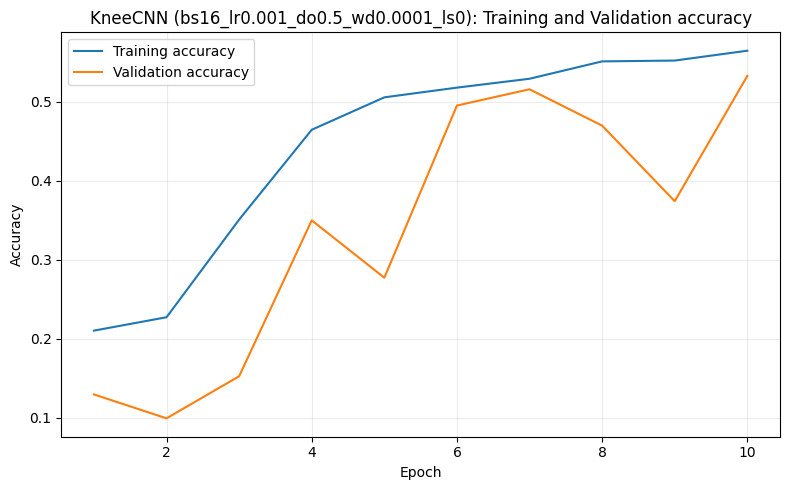

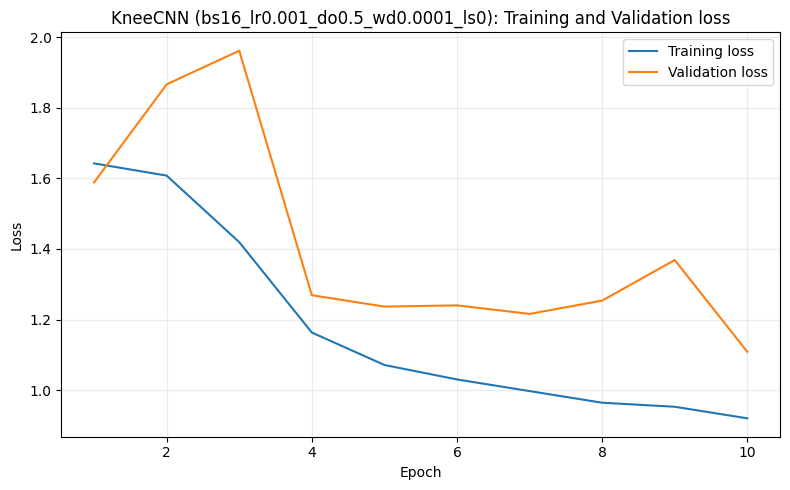


========== bs16_lr0.0003_do0.5_wd0.0001_ls0 ==========


Epoch [1/10] | Train:   0%|          | 0/362 [00:00<?, ?it/s]

Epoch [1/10] | Validate:   0%|          | 0/52 [00:00<?, ?it/s]

Epoch [1/10] | Train Loss: 1.5833 | Train Acc: 24.77% | Val Loss: 1.5404 | Val Acc: 26.39% | Val AUROC: 0.6584


Epoch [2/10] | Train:   0%|          | 0/362 [00:00<?, ?it/s]

...

Epoch [9/10] | Validate:   0%|          | 0/52 [00:00<?, ?it/s]

Epoch [9/10] | Train Loss: 0.8987 | Train Acc: 58.62% | Val Loss: 1.1217 | Val Acc: 52.91% | Val AUROC: 0.8167


Epoch [10/10] | Train:   0%|          | 0/362 [00:00<?, ?it/s]

Epoch [10/10] | Validate:   0%|          | 0/52 [00:00<?, ?it/s]

Epoch [10/10] | Train Loss: 0.8589 | Train Acc: 60.94% | Val Loss: 1.0181 | Val Acc: 57.02% | Val AUROC: 0.8268


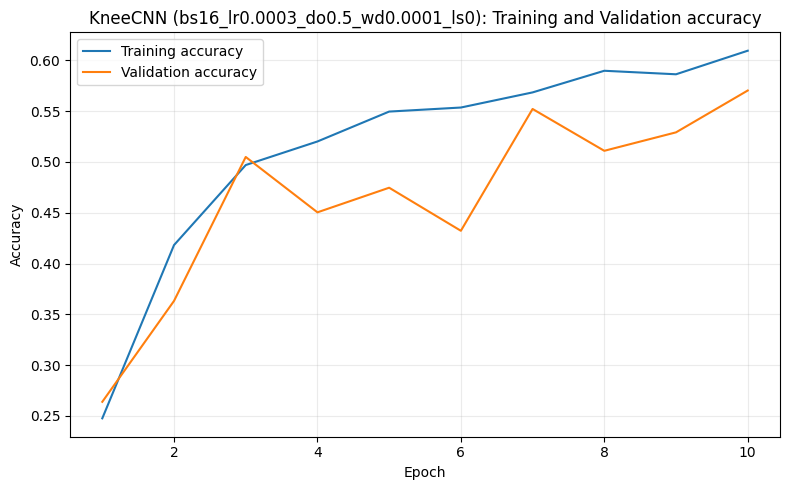

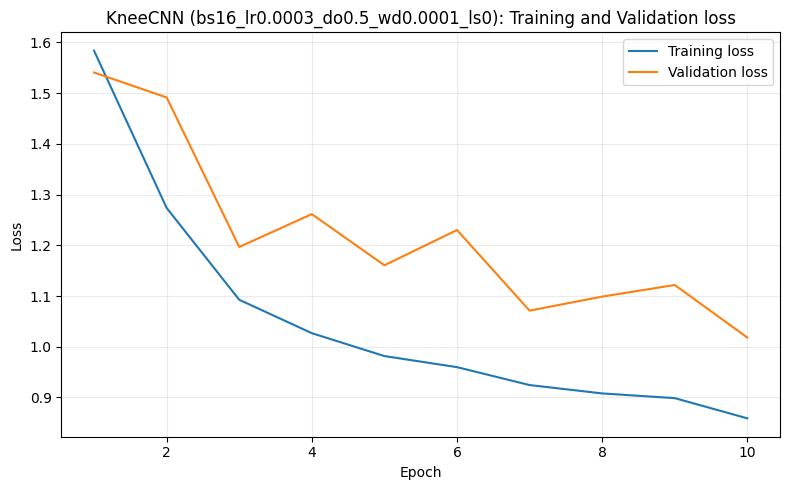


========== bs16_lr0.0001_do0.5_wd0.0001_ls0 ==========


Epoch [1/10] | Train:   0%|          | 0/362 [00:00<?, ?it/s]

Epoch [1/10] | Validate:   0%|          | 0/52 [00:00<?, ?it/s]

Epoch [1/10] | Train Loss: 1.6212 | Train Acc: 21.88% | Val Loss: 1.4367 | Val Acc: 36.68% | Val AUROC: 0.6570


Epoch [2/10] | Train:   0%|          | 0/362 [00:00<?, ?it/s]

...

Epoch [9/10] | Validate:   0%|          | 0/52 [00:00<?, ?it/s]

Epoch [9/10] | Train Loss: 0.8234 | Train Acc: 62.53% | Val Loss: 1.4232 | Val Acc: 39.83% | Val AUROC: 0.7937


Epoch [10/10] | Train:   0%|          | 0/362 [00:00<?, ?it/s]

Epoch [10/10] | Validate:   0%|          | 0/52 [00:00<?, ?it/s]

Epoch [10/10] | Train Loss: 0.7889 | Train Acc: 64.47% | Val Loss: 1.0143 | Val Acc: 58.35% | Val AUROC: 0.8403


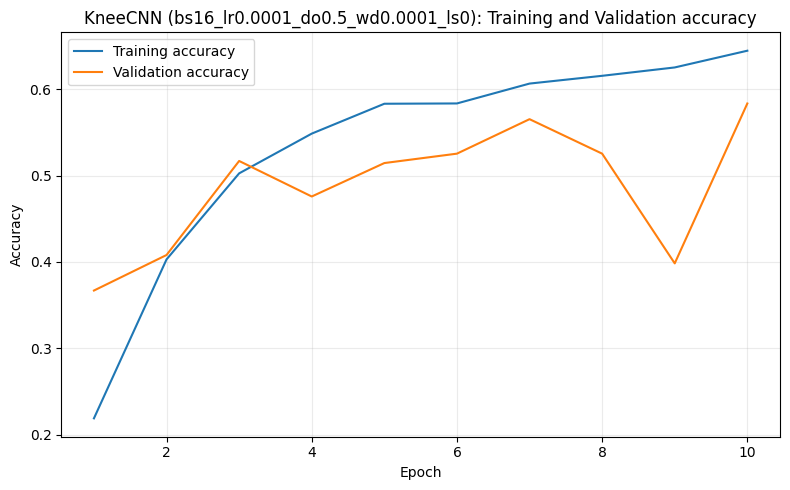

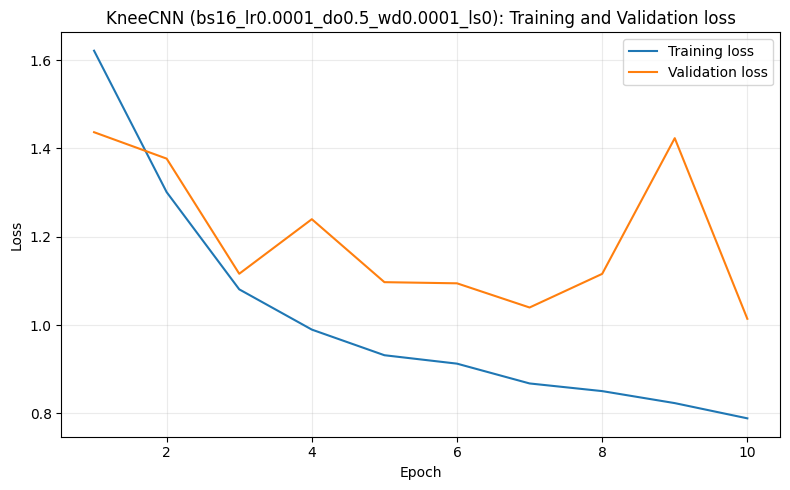


========== bs32_lr0.001_do0.5_wd0.0001_ls0 ==========


Epoch [1/10] | Train:   0%|          | 0/181 [00:00<?, ?it/s]

Epoch [1/10] | Validate:   0%|          | 0/26 [00:00<?, ?it/s]

Epoch [1/10] | Train Loss: 1.6340 | Train Acc: 19.42% | Val Loss: 1.6184 | Val Acc: 12.71% | Val AUROC: 0.5271


Epoch [2/10] | Train:   0%|          | 0/181 [00:00<?, ?it/s]

...

Epoch [9/10] | Validate:   0%|          | 0/26 [00:00<?, ?it/s]

Epoch [9/10] | Train Loss: 0.9623 | Train Acc: 54.62% | Val Loss: 1.1669 | Val Acc: 52.18% | Val AUROC: 0.7894


Epoch [10/10] | Train:   0%|          | 0/181 [00:00<?, ?it/s]

Epoch [10/10] | Validate:   0%|          | 0/26 [00:00<?, ?it/s]

Epoch [10/10] | Train Loss: 0.9188 | Train Acc: 56.25% | Val Loss: 1.2257 | Val Acc: 50.48% | Val AUROC: 0.7822


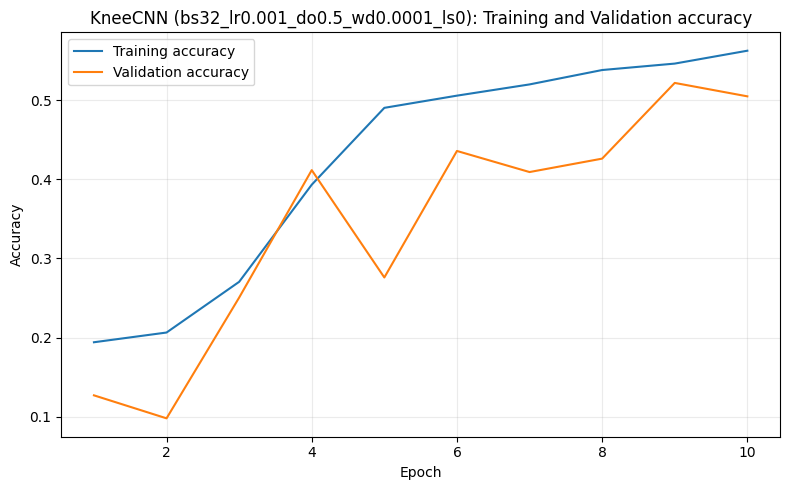

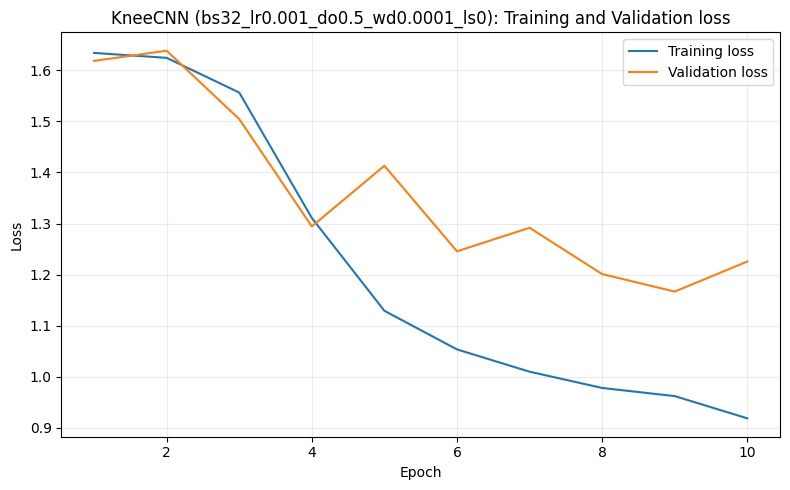


========== bs32_lr0.0003_do0.5_wd0.0001_ls0 ==========


Epoch [1/10] | Train:   0%|          | 0/181 [00:00<?, ?it/s]

Epoch [1/10] | Validate:   0%|          | 0/26 [00:00<?, ?it/s]

Epoch [1/10] | Train Loss: 1.6169 | Train Acc: 21.70% | Val Loss: 1.4095 | Val Acc: 38.38% | Val AUROC: 0.6212


Epoch [2/10] | Train:   0%|          | 0/181 [00:00<?, ?it/s]

...

Epoch [9/10] | Validate:   0%|          | 0/26 [00:00<?, ?it/s]

Epoch [9/10] | Train Loss: 0.8672 | Train Acc: 59.36% | Val Loss: 1.1081 | Val Acc: 55.08% | Val AUROC: 0.8186


Epoch [10/10] | Train:   0%|          | 0/181 [00:00<?, ?it/s]

Epoch [10/10] | Validate:   0%|          | 0/26 [00:00<?, ?it/s]

Epoch [10/10] | Train Loss: 0.8231 | Train Acc: 61.91% | Val Loss: 1.0629 | Val Acc: 56.66% | Val AUROC: 0.8287


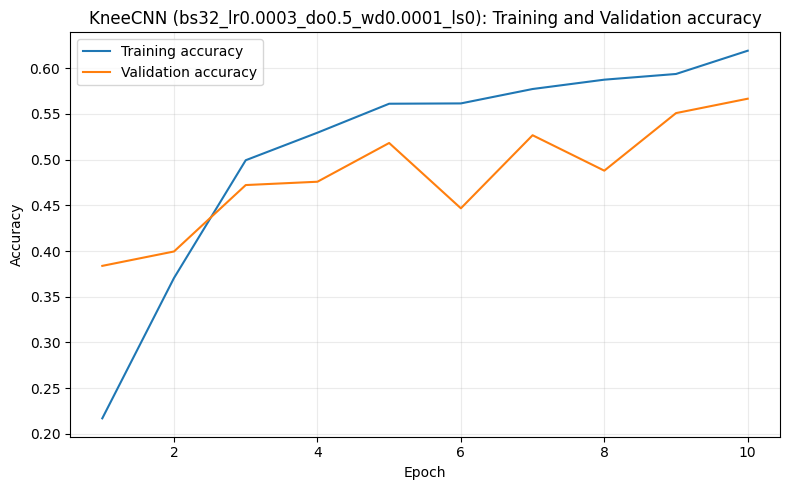

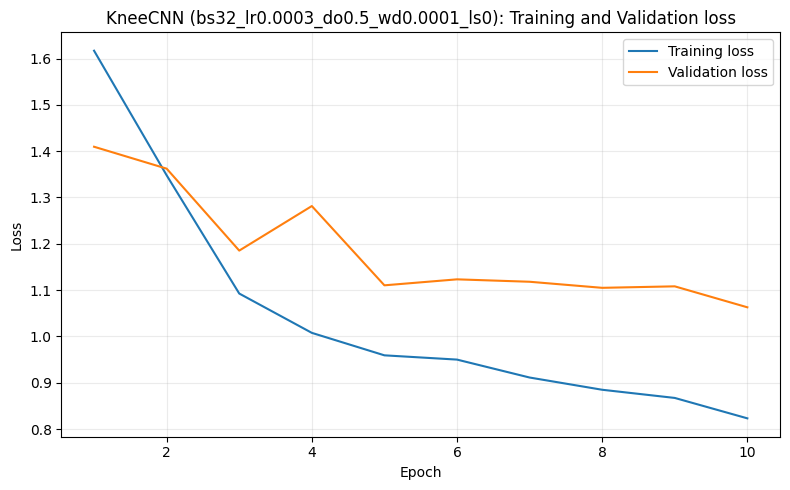

In [7]:
histories = {}
from src.metrics import plot_training_history

# Gives the true grades and the predicted probabilities (softmax) for one loader
@torch.no_grad()
def get_predictions(model, loader):
    model.eval()
    actual, probs = [], []
    for x, y in loader:
        logits = model(x.to(DEVICE))
        actual.append(y.numpy())
        probs.append(torch.softmax(logits, dim=1).cpu().numpy())
    return np.concatenate(actual), np.concatenate(probs)

for config in CONFIGS:
    run_name = config_name(config)
    print(f"\n========== {run_name} ==========")

    # Loss for this run (label smoothing 0 = normal cross-entropy); run_epoch uses "criterion"
    criterion = nn.CrossEntropyLoss(label_smoothing=config['label_smoothing'])

    # Same start for every run
    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)

    loaders = make_loaders(config['batch_size'])

    # Create KneeCNN with 5 output classes and move it to the gpu
    model = KneeCNN(NUM_CLASSES, dropout=config['dropout']).to(DEVICE)

    # Train all parameters (no pretrained layers to freeze)
    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=config['lr'],
        weight_decay=config['weight_decay']
    )

    history = []
    best_val_auroc = -1.0
    # Stops model after 4 epochs of not improving validation AUROC
    early_stop_rate = 4
    epochs_without_improvement = 0
    # Reduce learning rate when validation AUROC stagnates ("max" = higher is better)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode="max",
        factor=0.5,
        patience=2
    )

    for epoch in range(1, NUM_EPOCHS + 1):
        train_stats = run_epoch(
            model, loaders['train'], optimizer,
            epoch=epoch, num_epochs=NUM_EPOCHS
        )

        val_stats = run_epoch(
            model, loaders['val'],
            epoch=epoch, num_epochs=NUM_EPOCHS
        )

        # Validation AUROC of this epoch
        y_val, val_prob = get_predictions(model, loaders['val'])
        val_auroc = roc_auc_score(y_val, val_prob, multi_class='ovr', average='macro')

        history.append({
          'epoch': epoch,
          'train_loss': train_stats['loss'],
          'train_accuracy': train_stats['accuracy'],
          'val_loss': val_stats['loss'],
          'val_accuracy': val_stats['accuracy'],
          'val_auroc': val_auroc
        })

        tqdm.write(
          f"Epoch [{epoch}/{NUM_EPOCHS}] | "
          f"Train Loss: {train_stats['loss']:.4f} | "
          f"Train Acc: {train_stats['accuracy']:.2%} | "
          f"Val Loss: {val_stats['loss']:.4f} | "
          f"Val Acc: {val_stats['accuracy']:.2%} | "
          f"Val AUROC: {val_auroc:.4f}"
        )

        scheduler.step(val_auroc)

        # Save the model if validation AUROC improved, otherwise count
        if val_auroc > best_val_auroc:
            best_val_auroc = val_auroc
            epochs_without_improvement = 0
            # Save best model
            torch.save(model.state_dict(), CHECKPOINT_DIR / f"best_kneecnn_{run_name}.pth")
        else:
            epochs_without_improvement += 1

        if epochs_without_improvement >= early_stop_rate:
            print("Early stopping triggered!")
            break

    histories[run_name] = history

    # Plot training metrics over epochs
    plot_training_history(
        history,
        output_dir=OUTPUT_DIR / "metrics",
        model_name=f"KneeCNN ({run_name})",
        show_plots = True,
        save_plots = False
    )

## 2.2.2 Validation predictions and metrics

Each run's best model (highest validation AUROC) is tested on the validation set. AUROC is calculated as in `02_transfer_learning.ipynb`: softmax probabilities, one-vs-rest per grade, macro average.

`best_val_loss` is not comparable between runs with and without label smoothing (smoothing raises the loss), so we compare the runs with the AUROC.

The table also shows how well each run handles the difficult grades: **balanced accuracy**, **macro F1** and the **recall of KL1, KL2 and KL4** (share of real KL1/KL2/KL4 knees that were found). The run with the highest validation AUROC is used for the final test.

In [8]:
from sklearn.metrics import balanced_accuracy_score, f1_score, recall_score

def summarize_metrics(y_true, probabilities, class_names):
    predictions = probabilities.argmax(axis=1)
    results = {'accuracy': accuracy_score(y_true, predictions)}
    present = np.unique(y_true)
    if len(class_names) == 2 and len(present) == 2:
        results['auroc'] = roc_auc_score(y_true, probabilities[:, 1])
    elif len(present) == len(class_names):
        results['auroc'] = roc_auc_score(
            y_true, probabilities, labels=np.arange(len(class_names)),
            multi_class='ovr', average='macro')
    else:
        results['auroc'] = float('nan')
        print('AUROC undefined: not all classes appear in this validation split.')
    return results, confusion_matrix(y_true, predictions,
                                      labels=np.arange(len(class_names)))

comparison = []
for config in CONFIGS:
    run_name = config_name(config)
    model = KneeCNN(NUM_CLASSES, dropout=config['dropout']).to(DEVICE)
    model.load_state_dict(torch.load(CHECKPOINT_DIR / f"best_kneecnn_{run_name}.pth",
                                     map_location=DEVICE, weights_only=True))

    y_val, val_prob = get_predictions(model, make_loaders(config['batch_size'])['val'])
    val_pred = val_prob.argmax(axis=1)
    metrics, cm = summarize_metrics(y_val, val_prob, class_names)
    print(f'\n===== {run_name} =====')
    print('Validation metrics:', metrics)
    print('Confusion matrix (rows=true, cols=predicted):')
    display(pd.DataFrame(cm, index=class_names, columns=class_names))

    recall = recall_score(y_val, val_pred, labels=np.arange(NUM_CLASSES), average=None, zero_division=0)
    comparison.append({
        'run': run_name,
        **config,
        'val_auroc': metrics['auroc'],
        'val_accuracy': metrics['accuracy'],
        'val_balanced_accuracy': balanced_accuracy_score(y_val, val_pred),
        'val_macro_f1': f1_score(y_val, val_pred, average='macro', zero_division=0),
        'recall_KL1': recall[1],
        'recall_KL2': recall[2],
        'recall_KL4': recall[4],
        'best_epoch': max(histories[run_name], key=lambda h: h['val_auroc'])['epoch'],
        'epochs_run': len(histories[run_name]),
    })

comparison = pd.DataFrame(comparison).sort_values('val_auroc', ascending=False).reset_index(drop=True)
display(comparison.round(4))

BEST_RUN = comparison.loc[0, 'run']
BEST_CONFIG = next(c for c in CONFIGS if config_name(c) == BEST_RUN)
BEST_BATCH_SIZE = BEST_CONFIG['batch_size']
print('Best setting (highest validation AUROC):', BEST_RUN)

best_model = KneeCNN(NUM_CLASSES, dropout=BEST_CONFIG['dropout']).to(DEVICE)
best_model.load_state_dict(torch.load(CHECKPOINT_DIR / f"best_kneecnn_{BEST_RUN}.pth",
                                      map_location=DEVICE, weights_only=True))


===== bs16_lr0.001_do0.5_wd0.0001_ls0 =====
Validation metrics: {'accuracy': 0.5326876513317191, 'auroc': np.float64(0.7872600166886574)}
Confusion matrix (rows=true, cols=predicted):


,0,1,2,3,4
0,268,1,50,7,2
1,105,1,39,8,0
2,105,0,92,15,0
3,6,0,36,57,7
4,0,0,1,4,22



===== bs16_lr0.0003_do0.5_wd0.0001_ls0 =====
Validation metrics: {'accuracy': 0.5702179176755447, 'auroc': np.float64(0.8268467377067035)}
Confusion matrix (rows=true, cols=predicted):


,0,1,2,3,4
0,252,17,49,8,2
1,86,5,53,9,0
2,56,9,127,18,2
3,0,4,25,62,15
4,1,0,0,1,25



===== bs16_lr0.0001_do0.5_wd0.0001_ls0 =====
Validation metrics: {'accuracy': 0.5835351089588378, 'auroc': np.float64(0.8403426792136907)}
Confusion matrix (rows=true, cols=predicted):


...


===== bs32_lr0.0003_do0.5_wd0.0001_ls0 =====
Validation metrics: {'accuracy': 0.5665859564164649, 'auroc': np.float64(0.82866684109326)}
Confusion matrix (rows=true, cols=predicted):


,0,1,2,3,4
0,189,57,72,9,1
1,45,31,68,8,1
2,19,22,148,19,4
3,2,3,17,74,10
4,0,0,0,1,26


,run,batch_size,lr,dropout,weight_decay,label_smoothing,val_auroc,val_accuracy,val_balanced_accuracy,val_macro_f1,recall_KL1,recall_KL2,recall_KL4,best_epoch,epochs_run
0,bs16_lr0.0001_do0.5_wd0.0001_ls0,16,0.0001,0.5,0.0001,0.0,0.8403,0.5835,0.6206,0.5629,0.1111,0.6887,0.9630,10,10
1,bs32_lr0.0003_do0.5_wd0.0001_ls0,32,0.0003,0.5,0.0001,0.0,0.8287,0.5666,0.6276,0.5779,0.2026,0.6981,0.9630,10,10
2,bs16_lr0.0003_do0.5_wd0.0001_ls0,16,0.0003,0.5,0.0001,0.0,0.8268,0.5702,0.5822,0.5215,0.0327,0.5991,0.9259,10,10
3,bs32_lr0.001_do0.5_wd0.0001_ls0,32,0.0010,0.5,0.0001,0.0,0.7894,0.5218,0.5203,0.5062,0.1046,0.5660,0.5185,9,10
4,bs16_lr0.001_do0.5_wd0.0001_ls0,16,0.0010,0.5,0.0001,0.0,0.7873,0.5327,0.5220,0.4876,0.0065,0.4340,0.8148,10,10


Best setting (highest validation AUROC): bs16_lr0.0001_do0.5_wd0.0001_ls0


<All keys matched successfully>

## **7**. Detailed CNN evaluation

⚠️ This uses the **test set**: run it only once, with the best setting from 2.2.2.

Current backend: module://matplotlib_inline.backend_inline
True labels: (1656,)
Predicted probabilities: (1656, 5)


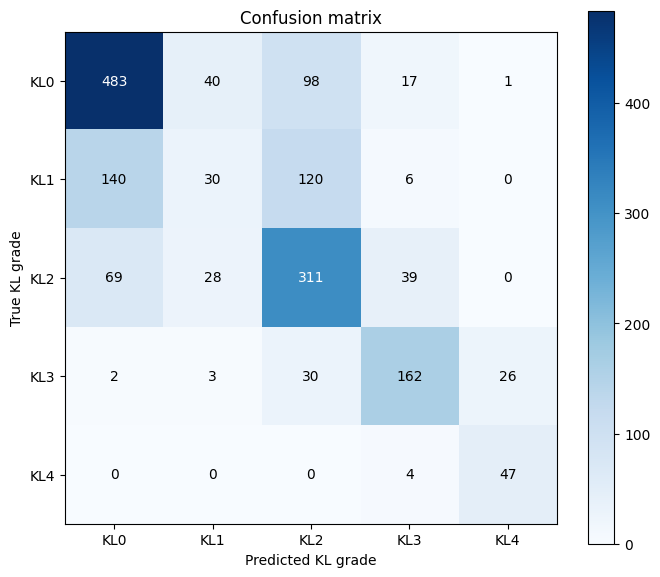

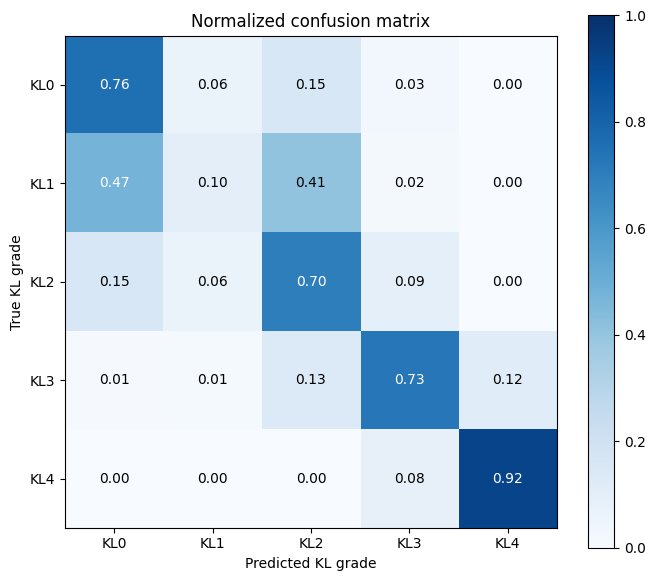

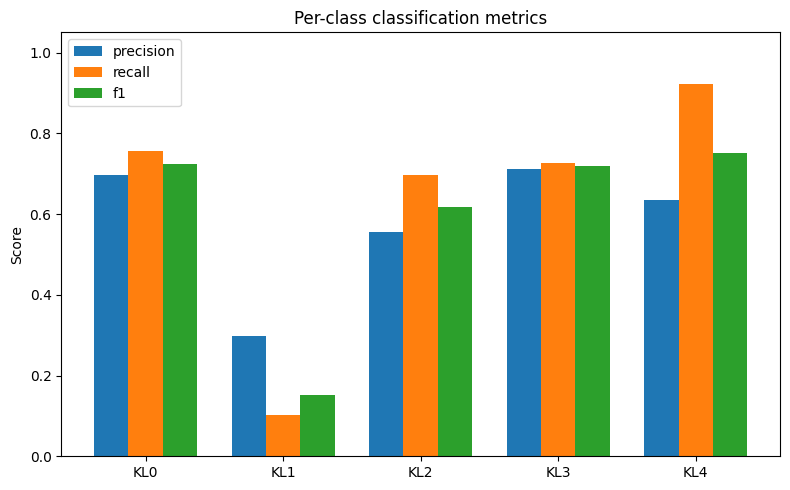

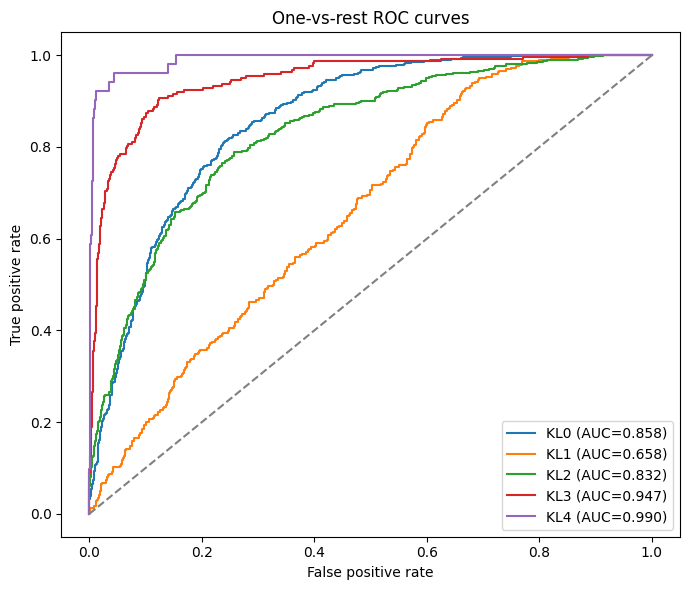

{'model_name': 'KneeCNN (bs16_lr0.0001_do0.5_wd0.0001_ls0)', 'n_samples': 1656, 'accuracy': 0.623792270531401, 'balanced_accuracy': 0.6401990726444586, 'macro_f1': 0.5929016955346327, 'weighted_f1': 0.5934411357774213, 'quadratic_weighted_kappa': 0.7364574828243984, 'mae': 0.5072463768115942, 'macro_auroc_ovr': 0.8570588300620047}


In [9]:
import matplotlib
import matplotlib.pyplot as plt

plt.switch_backend("module://matplotlib_inline.backend_inline")

print("Current backend:", matplotlib.get_backend())

# Generate predictions
y_test, test_prob = get_predictions(best_model, make_loaders(BEST_BATCH_SIZE)["test"])

print("True labels:", y_test.shape)
print("Predicted probabilities:", test_prob.shape)

from src.metrics import evaluate_predictions

# Evaluate CNN performance
results = evaluate_predictions(
    y_true=y_test,
    y_prob=test_prob,
    model_name=f"KneeCNN ({BEST_RUN})",
    show_plots=True,
    save_plots=False
)

print(results)

In [18]:
from google.colab import files
from pathlib import Path

# Nimmt die hochgeladene Datei aus /content
NOTEBOOK = [p for p in Path('/content').glob('*.ipynb')][0]
print('Notebook:', NOTEBOOK)

!jupyter nbconvert --to html "{NOTEBOOK}" --output-dir /content --output custom_cnn_tuning_round1
files.download('/content/custom_cnn_tuning_round1.html')

IndexError: list index out of range